# Analysis of the Amazon UK Price Prediction dataset

In [1]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

## Initial Assessment

In [2]:
df.shape

(2443651, 9)

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df = df.set_index('uid')

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 2443651 entries, 1 to 2828593
Data columns (total 8 columns):
 #   Column             Dtype  
---  ------             -----  
 0   asin               str    
 1   title              str    
 2   stars              float64
 3   reviews            int64  
 4   price              float64
 5   isBestSeller       bool   
 6   boughtInLastMonth  int64  
 7   category           str    
dtypes: bool(1), float64(2), int64(2), str(3)
memory usage: 151.5 MB


In [6]:
df.describe().round(2)

,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00
mean,2.15,480.63,89.24,25.90
std,2.19,5944.12,345.61,240.48
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,9.99,0.00
50%,0.00,0.00,19.09,0.00
75%,4.40,59.00,45.99,0.00
max,5.00,1356658.00,100000.00,50000.00


In [7]:
df.isna().sum()

asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

## Part 1: Understanding Product Categories

*Business Question*: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Generate a frequency table for the product ```category```.
2. Which are the top 5 most listed product categories?
3. Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
4. For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [8]:
category_freuqency: pd.Series = df["category"].value_counts()
category_freuqency.head(10)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [9]:
top_5_categories = category_freuqency.head(5)
print(top_5_categories.index.to_list())

['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']


The top 5 categories are: ```Sports & Outdoors```, ```Beauty```, ```Handmade Clothing, Shoes & Accessories```, ```Bath & Body```, ```Birthday Gifts```. These are the most important product categories, with ```Sports & Outdoors``` vastly dominating over all others.

<Axes: title={'center': 'Top 30 categories'}, xlabel='category'>

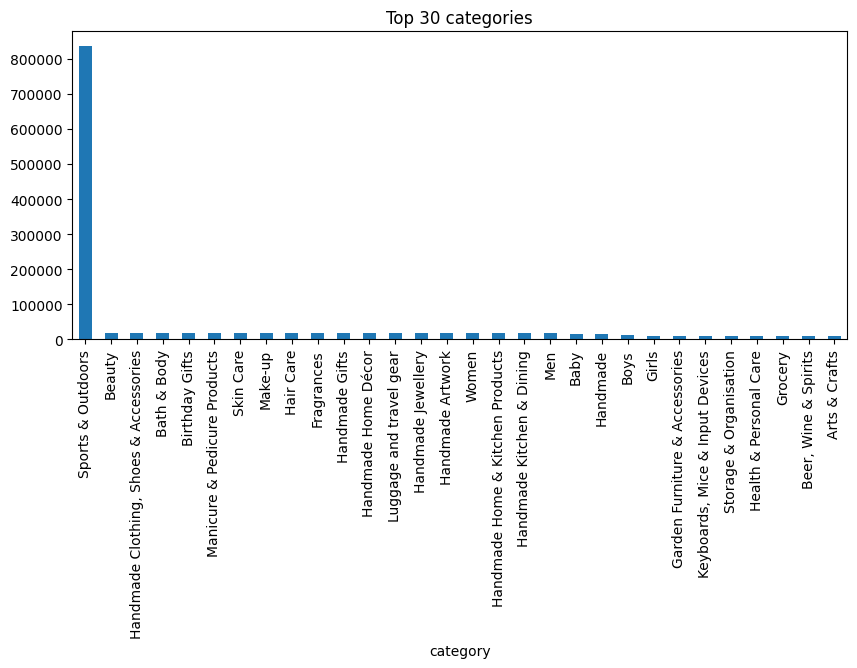

In [10]:
category_freuqency.head(30).plot.bar(figsize=(10, 4), title="Top 30 categories")

<Axes: title={'center': 'Top 10 categories'}>

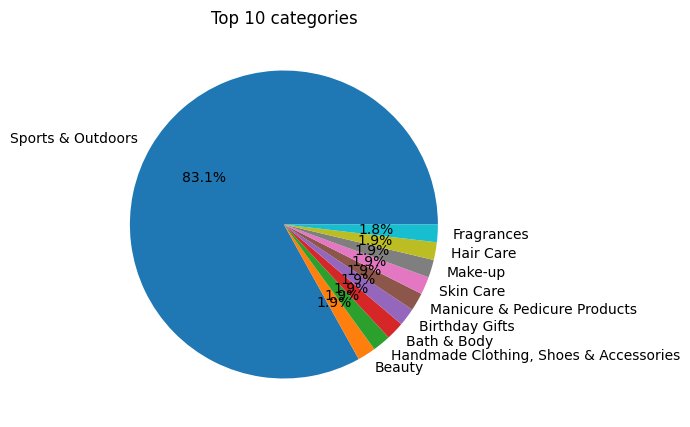

In [11]:
category_freuqency.head(10).plot.pie(figsize=(10, 5), autopct='%1.1f%%', title="Top 10 categories")

## Part 2: Delving into Product Pricing

*Business Question*: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. Calculate the mean, median, and mode for the ```price``` of products.
2. What's the average price point of products listed? How does this compare with the most common price point (mode)?
3. Determine the variance, standard deviation, range, and interquartile range for product ```price```.
4. How varied are the product prices? Are there any indicators of a significant spread in prices?
5. Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
6. Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


In [13]:
price_series: pd.Series = df.price
price_series.describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [14]:
median_price: float = price_series.median()
mode_prices: list[float] = price_series.mode().tolist()

print("Median price:", median_price)
print("Price modes:", mode_prices)

Median price: 19.09
Price modes: [9.99]


The ```average``` price for products is 89$, whereas the ```mode``` is only 9.99$. The ```median``` price is also on the lower end, at 19.09$. This suggests that the most frequent prices tend towards the lower end of the range, and that there possibly are some outlier prices. A proper conclusion in this regard needs to also consider measures of dispersion.

In [15]:
price_range: float = price_series.max() - price_series.min()
price_variance: float = price_series.var().__round__(2)

print("Price range:", price_range)
print("Price variance:", price_variance)

Price range: 100000.0
Price variance: 119445.49


The measures of dispersion make it clear that there are major variation in prices, indicating outliers in higher end of the range. First, ```range```, ```variance``` and ```standard deviation``` are quite high values. This is even more evident when taking into account the interquitile range: with a minimum price of 0.00$, 25% of products cost 9.99$ or less, 50% cost 19.09$ or less, and 75% cost 45.99$ or less! This means that only 25% products is above the 45.99$ threshold. However, since the max price is 100k, we can reasonably assume that an even smaller percentage of products is much more expensive than 45.99$.

<Axes: title={'center': 'Price range'}, ylabel='Frequency'>

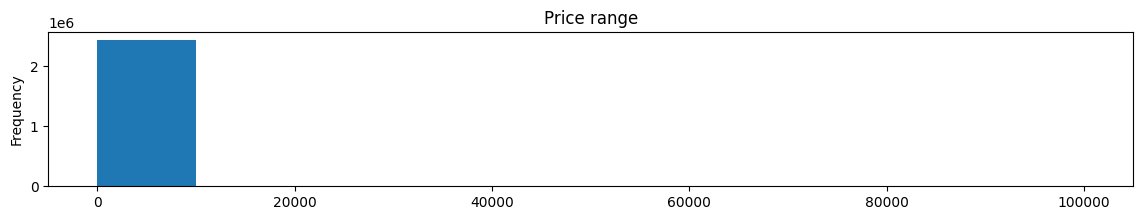

In [41]:
price_series.plot.hist(figsize=(14, 2), title="Price range")

This histogram is hard to visualize because, according to the data discovered so far, the vast majority of the products cost less than 100$. This visualization has the include a notable outlier (100k) and therefore concentrates all datapoints withing the 10k mark. A solution to this would be to extract multiple random samples of data, say 20% of the dataset, and see how the distribution behaves.

<Axes: title={'center': 'Price range'}, ylabel='Frequency'>

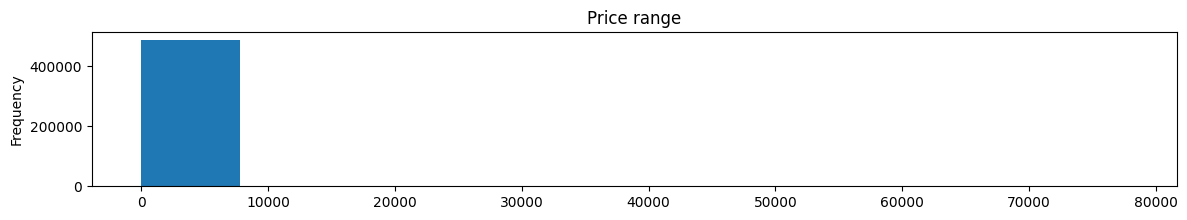

In [54]:
price_series.sample(frac=0.2, random_state=42).plot.hist(figsize=(14, 2), title="Price range")

The assummption was wrong. Evidently there are multiple outliers that make it difficult to observe actual distribution with random sampling alone.

<Axes: title={'center': 'Price range'}, ylabel='Frequency'>

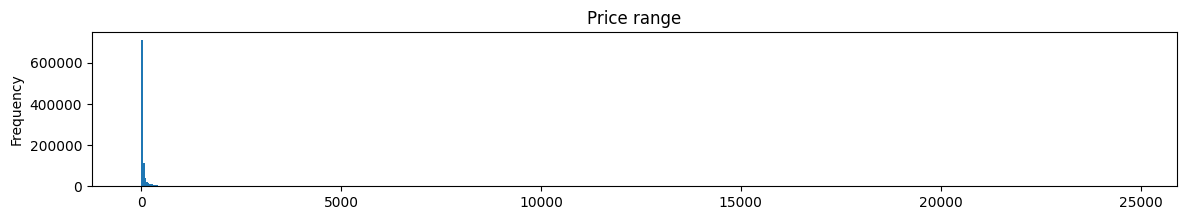

In [56]:
price_series.sample(frac=0.4, random_state=44).plot.hist(bins=600, figsize=(14, 2), title="Price range")

<Axes: title={'center': 'Price range'}, ylabel='Frequency'>

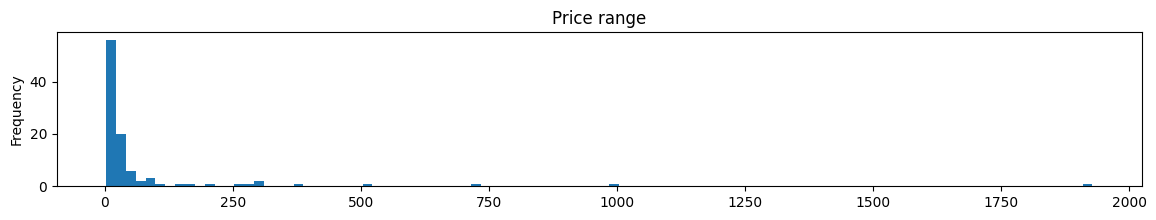

In [65]:
price_series.sample(n=100, random_state=12).plot.hist(bins=100, figsize=(14, 2), title="Price range")

Setting a specified number of sample data and bins for the histogram allows to understand data distribution a little better, but still on a very high level. The visualization is so poorly detailed that it's difficult to make strong observations.

<Axes: >

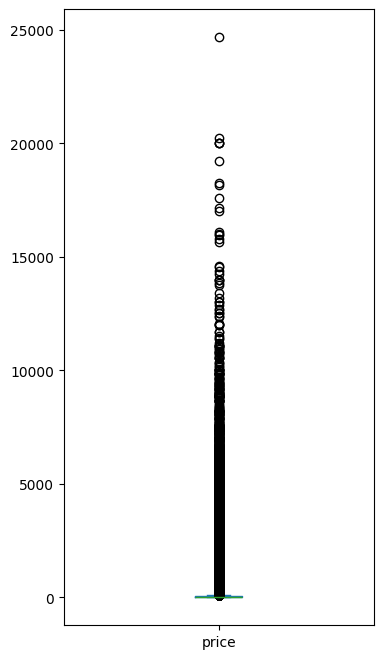

In [59]:
price_series.sample(frac=0.4, random_state=44).plot.box(figsize=(4, 8))

Using a box plot gives us some more useful insight. Still sampling only part of the data, we can observe how densely concentrated the data points are towards the lower end of the price range. The higher the price, the more sparse and 'exceptional' the data. There are some definite outliers in this dataset.

## Part 3: Unpacking Product Ratings

*Business Question*: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. Calculate the mean, median, and mode for the ```rating``` of products.
2. How do customers generally rate products? Is there a common trend?
3. Determine the variance, standard deviation, and interquartile range for product ```rating```.
4. Are the ratings consistent, or is there a wide variation in customer feedback?
5. Calculate the skewness and kurtosis for the ```rating``` column.
6. Are the ratings normally distributed, or do they lean towards higher or lower values?
7. Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [69]:
rating_series: pd.Series = df.stars
rating_series.describe().round(1)

count    2443651.0
mean           2.2
std            2.2
min            0.0
25%            0.0
50%            0.0
75%            4.4
max            5.0
Name: stars, dtype: float64

In [67]:
median_rating: float = rating_series.median()
modes_rating: list[float] = rating_series.mode().tolist()

print("Median rating:", median_rating)
print("Rating modes:", modes_rating)

Median rating: 0.0
Rating modes: [0.0]


While the ```average``` rating is only about 2 stars, ```median``` and ```mode``` are 0. Rather than negative ratings, this seems to suggest that the majority of customers abstains from rating products.

In [70]:
rating_range: float = rating_series.max() - rating_series.min()
rating_variance: float = rating_series.var().__round__(1)

print("Rating range:", rating_range)
print("Rating variance:", rating_variance)

Rating range: 5.0
Rating variance: 4.8


Accoring to the measures of dispersion, we can corroborate the previous observation: there is a wide gap in customers rating, with at least 50% of customers not rating products at all. We can further observe that the ones that do rate products tend to rate them on the higher end of the scale, giving between 4 and 5 stars.

In [ ]:
rating_skewness = rating_series.skew().round(2)
rating_kurtosis = rating_series.kurtosis().round(2)

print("Rating series skewness:", rating_skewness)
print("Rating series kurtosis:", rating_kurtosis)

Rating series skewness: 0.08
Rating series kurtosis: -1.93


The ratings are not normally distributed, as their frequency tends to peak at the extreme values: either 0 (non-rated products) or 4/5 stars (the highest rating). In fact, ```skewness``` is very close to 0 (0.08), and the ```kurtosis``` is negative, suggesting lighter tails and no peak around the mean.

<Axes: title={'center': 'Ratings Distribution'}, ylabel='Frequency'>

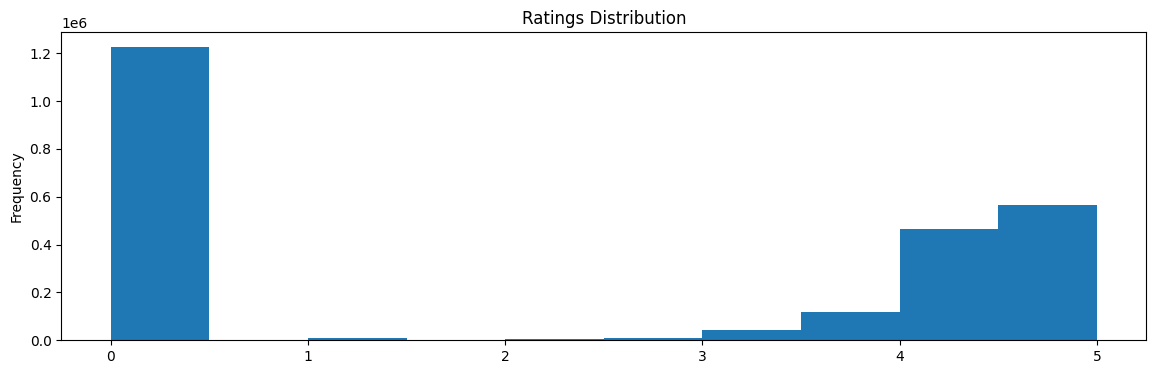

In [86]:
rating_series.plot.hist(title="Ratings Distribution", figsize=(14, 4))

With this final visualization we can confirm the intuition obtained from numbers: the most common rating is 0 (i.e. customers not rating the products).

## 